# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [11]:
SOURCE_URL = "https://www2.census.gov/programs-surveys/acs/data/pums/2024/1-Year/"
DOWNLOAD_DATE = "2026-11-01"
FILE_NAME = "ma_acs_2024_analysis.csv"

I am using data from the U.S. Census Bureau's 2024 American Community Survey (ACS), specifically the Massachusetts person-level dataset. Each observation represents one person, and the data only cover 2024.

My dependent variable is annual earnings, which includes differences in both pay and how much someone works throughout the year. I narrowed my sample to adults ages 25–64 with positive earnings. Although there are no missing values in my final analysis variables, this restriction means my results will not represent everyone in Massachusetts, particularly those without earnings.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [12]:
DATA_URL = "https://raw.githubusercontent.com/rohit-jain8/econ3916-education-earnings/main/ma_acs_2024_analysis.csv"
pd.read_csv(DATA_URL).to_csv("ma_acs_2024_analysis.csv", index=False)
print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [13]:
from pathlib import Path
import os
# For Colab, upload the data CSV into data/ or clone the repository before running.
path = Path(FILE_NAME)
if not path.exists():
    raise FileNotFoundError(f"Place {FILE_NAME} in the Colab working directory (or clone the repo first).")
df = pd.read_csv(path)
assert len(df)==31442
assert df[['PERNP','SCHL','AGEP','SEX','PWGTP','log_earnings']].notna().all().all()
print('Rows, columns:',df.shape)
print('Missing values by column:')
print(df.isna().sum().to_string())
print('Education group counts:')
print(df.education.value_counts().to_string())
print('Summary statistics:')
print(df[['PERNP','log_earnings','AGEP','PWGTP','WKHP','WKWN']].describe().round(2).to_string())

Rows, columns: (31442, 14)
Missing values by column:
SERIALNO              0
SPORDER               0
PWGTP                 0
AGEP                  0
SCHL                  0
SEX                   0
PERNP                 0
WKHP                  0
WKWN                  0
education             0
log_earnings          0
age_squared           0
female                0
fulltime_yearround    0
Education group counts:
education
Bachelor's                  9856
Graduate                    9111
Some college / associate    5796
High school                 5261
Less than high school       1418
Summary statistics:
            PERNP  log_earnings      AGEP     PWGTP      WKHP      WKWN
count    31442.00      31442.00  31442.00  31442.00  31442.00  31442.00
mean     97781.72         11.05     43.99    101.23     39.76     48.69
std     104391.74          1.09     11.62     80.91     11.11      9.64
min         20.00          3.00     25.00      1.00      1.00      1.00
25%      40000.00         10.60 

In [14]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "Massachusetts person ages 25–64 with positive annual earnings"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "log_earnings"     # your dependent variable's column name
MAIN_X = "education"      # your main explanatory variable's column name
CONTROLS = ["AGEP", "age_squared", "female"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 31,442   Columns: 14   One row is: Massachusetts person ages 25–64 with positive annual earnings

Missing values per column:
log_earnings    0
education       0
AGEP            0
age_squared     0
female          0

Skew of log_earnings: -1.51 (above about 1, consider a log)


**1. For each control: does your main explanatory variable change it?**

My controls are age, age squared, and sex. Education does not change someone's age or sex, so I think these are appropriate controls to include. I also included age squared because earnings may change at different rates throughout someone's career.

I did not include occupation or hours worked in my main regression because education could influence both of those factors. I will look at full-time, year-round workers separately to see whether the relationship between education and earnings changes for that group.

**2. Are all your variables in the same units and for the same years?**

Yes. All my variables come from the 2024 Massachusetts ACS dataset, and each observation represents an individual. Earnings are measured in annual dollars, education is divided into five categories, age is measured in years, and sex is represented by an indicator variable. Although the variables use different measurements, they all refer to the same individuals and year.

**3. If your question is about a policy, where is the period before it?**

My project is not evaluating a policy. I am looking at the relationship between education and earnings in 2024, so I do not need data from a period before a policy was introduced.

My research question is: How is educational attainment associated with annual earnings among adults ages 25–64 with positive earnings in Massachusetts in 2024, controlling for age and sex?

Following my professor's feedback, I grouped education into five categories: less than high school, high school/GED, some college or associate degree, bachelor's degree, and graduate degree. I will use high school/GED as the reference group so I can compare the other education levels against it.

My goal is to examine the relationship between education and earnings, rather than claim that education directly causes higher earnings.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

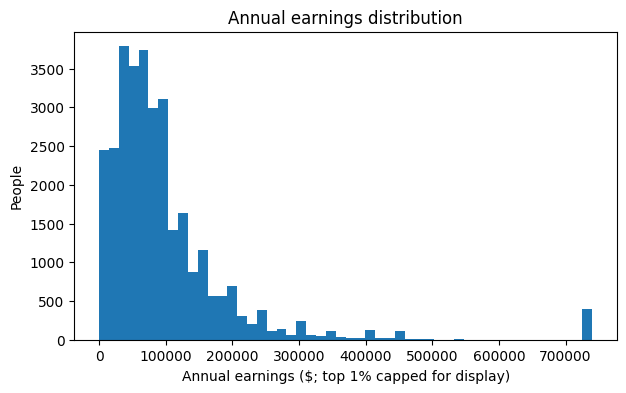

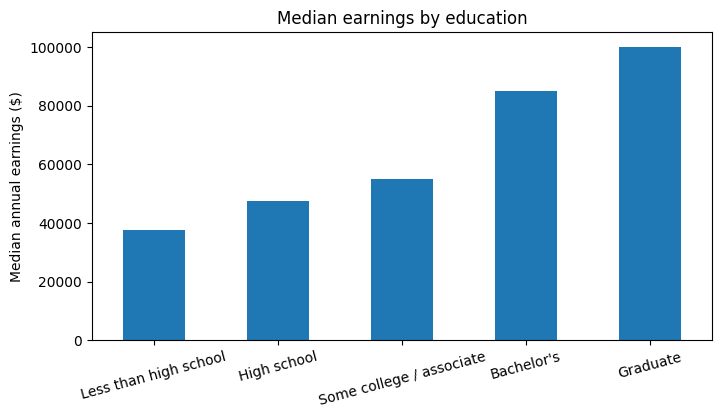

Median earnings by education: education
Less than high school        37650.0
High school                  47500.0
Some college / associate     55000.0
Bachelor's                   85000.0
Graduate                    100000.0


In [15]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,4))
cap=df.PERNP.quantile(.99)
ax.hist(df.PERNP.clip(upper=cap),bins=50)
ax.set(xlabel='Annual earnings ($; top 1% capped for display)',ylabel='People',title='Annual earnings distribution')
plt.show()
order=['Less than high school','High school','Some college / associate',"Bachelor's",'Graduate']
med=df.groupby('education').PERNP.median().reindex(order)
fig,ax=plt.subplots(figsize=(8,4))
med.plot.bar(ax=ax)
ax.set(xlabel='',ylabel='Median annual earnings ($)',title='Median earnings by education')
plt.xticks(rotation=15)
plt.show()
print('Median earnings by education:',med.to_string())

The first graph shows that annual earnings are heavily right-skewed, meaning most people earn considerably less than the highest earners in the dataset. I limited the graph to the 99th percentile to make the distribution easier to see, but I kept all observations in the regression. This also helps explain why I am using the natural logarithm of earnings.

The second graph compares median annual earnings across the five education groups. It shows that people with higher levels of education generally have higher annual earnings. However, these differences may also reflect how many hours or weeks people work, not just differences in pay.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [16]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
x=pd.get_dummies(df.education,prefix='Education',dtype=float).drop(columns=['Education_High school'])
x['Age']=df.AGEP.astype(float)
x['Age squared']=df.age_squared.astype(float)
x['Female']=df.female.astype(float)
x=sm.add_constant(x)
y=df.log_earnings
ols=sm.OLS(y,x).fit()
hc3=ols.get_robustcov_results(cov_type='HC3')
weighted=sm.WLS(y,x,weights=df.PWGTP).fit(cov_type='HC3')
ft=df.fulltime_yearround==1
fulltime=sm.OLS(y.loc[ft],x.loc[ft]).fit(cov_type='HC3')
reg_table=pd.DataFrame({'OLS coef':ols.params,'HC3 SE':hc3.bse,'HC3 p':hc3.pvalues,'Weighted coef':weighted.params,'Weighted HC3 SE':weighted.bse,'Full-time coef':fulltime.params,'Full-time HC3 SE':fulltime.bse})
print(reg_table.round(5).to_string())
print('OLS N:',int(ols.nobs),'R squared:',ols.rsquared)
print('Weighted N:',int(weighted.nobs),'Weighted R squared:',weighted.rsquared)
print('Full-time/year-round N:',int(fulltime.nobs))
print('Percent differences for education dummies relative to HS (exact exp(beta)-1):')
for col in x.columns:
    if col.startswith('Education_'):
        print(col,round(100*(np.exp(ols.params[col])-1),2),'%')

                                    OLS coef   HC3 SE  HC3 p  Weighted coef  Weighted HC3 SE  Full-time coef  Full-time HC3 SE
const                                8.53728  0.09279    0.0        8.68415          0.11527         9.23438           0.06707
Education_Bachelor's                 0.68960  0.01720    0.0        0.65275          0.02131         0.58953           0.01257
Education_Graduate                   0.92477  0.01735    0.0        0.88308          0.02213         0.78703           0.01275
Education_Less than high school     -0.36557  0.03649    0.0       -0.35333          0.04635        -0.24688           0.03167
Education_Some college / associate   0.16423  0.01926    0.0        0.13332          0.02464         0.12381           0.01359
Age                                  0.09600  0.00438    0.0        0.09006          0.00547         0.07444           0.00319
Age squared                         -0.00097  0.00005    0.0       -0.00091          0.00006        -0.00071   

I used an OLS regression to examine how education is associated with annual earnings while controlling for age and sex. I also included age squared because the relationship between age and earnings may not be constant throughout someone's career.

I used HC3 robust standard errors because differences in the spread of earnings could affect how reliable the usual standard errors are.

Following my professor's feedback, I also ran a weighted regression using the ACS person weights (`PWGTP`) to see how the results compare when accounting for the survey weights. I kept the regular OLS regression as my main model since that is what the assignment requires.

Finally, I looked separately at full-time, year-round workers, defined as people who usually work at least 35 hours per week and worked at least 50 weeks during the year. This helps me see whether the education and earnings relationship changes when focusing on people with more similar work schedules, although it does not completely eliminate differences in hours worked.

**Connection to Lab 14:** The residual plot follows Step 9, the Breusch–Pagan test follows Step 5, and Cook's distance follows Step 6. VIF is required by this midterm but is not demonstrated in the uploaded Lab 14. The five education groups are dummy variables, so the residuals against the main predictor are shown by group.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.
**Code note:** The diagnostics use `statsmodels` functions covered by the assignment. The Cook's distance calculation below uses matrix operations, which are more advanced Python than the basic regression code. It is included only to measure influence; it does not change the OLS estimates.


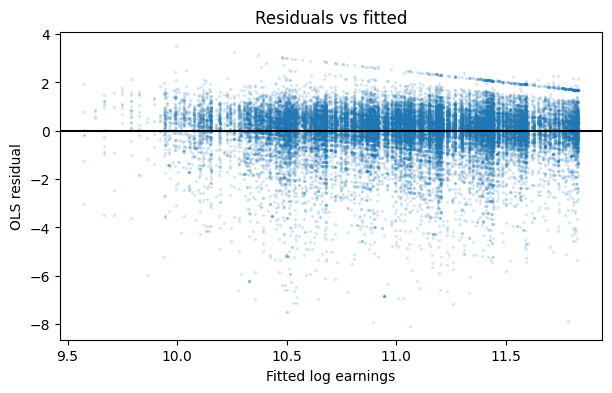

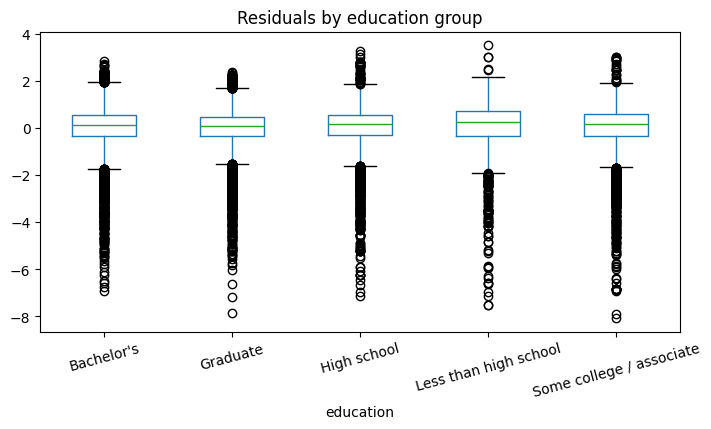

Breusch-Pagan LM statistic, p-value: (np.float64(110.25711057287482), np.float64(8.121121573615791e-21))
VIFs: Education_Bachelor's                   2.00
Education_Graduate                     1.98
Education_Less than high school        1.21
Education_Some college / associate     1.72
Age                                   79.21
Age squared                           79.19
Female                                 1.01
Five largest Cook’s distances:
Observation 20697 Cook D: 0.0056
Observation 19525 Cook D: 0.00551
Observation 5291 Cook D: 0.00551
Observation 16270 Cook D: 0.00484
Observation 25205 Cook D: 0.00428
Max Cook D: 0.005595080828942639 Count above 4/n: 1609
HC3 standard errors printed in Section 3.


In [17]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(ols.fittedvalues,ols.resid,s=2,alpha=.12)
ax.axhline(0,color='black')
ax.set(xlabel='Fitted log earnings',ylabel='OLS residual',title='Residuals vs fitted')
plt.show()
fig,ax=plt.subplots(figsize=(8,4))
df.assign(residual=ols.resid).boxplot(column='residual',by='education',ax=ax,rot=15,grid=False)
plt.suptitle('');plt.title('Residuals by education group');plt.show()
bp=het_breuschpagan(ols.resid,x)
print('Breusch-Pagan LM statistic, p-value:',bp[:2])
vifs=pd.Series({col:variance_inflation_factor(x.to_numpy(),i) for i,col in enumerate(x.columns) if col!='const'})
print('VIFs:',vifs.round(2).to_string())
# Lab 14, Step 6: use the built-in influence diagnostic instead of matrix algebra.
infl = ols.get_influence()
cook = infl.cooks_distance[0]
order = np.argsort(cook)[::-1][:5]
print("Five largest Cook’s distances:")
for i in order:
    print('Observation', i, 'Cook D:', round(cook[i], 5))
print('Max Cook D:', cook.max(), 'Count above 4/n:', int((cook > 4/len(df)).sum()))
print('HC3 standard errors printed in Section 3.')

I examined the residual plots to see whether there were any noticeable patterns that might suggest problems with my regression.

I also used the Breusch–Pagan test to check for heteroskedasticity. The test produced a very small p-value, so I rejected the assumption of constant error variance. Because of this, I used HC3 robust standard errors for my regression results.

I checked the VIF values to see whether any explanatory variables were strongly related to each other. Age and age squared are naturally related, so higher VIF values for those variables would not be surprising.

Finally, I used Cook's distance to identify observations that might have a large influence on the regression results. An observation having a high Cook's distance does not automatically mean it should be removed, but it is worth examining.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

One of the biggest limitations of my analysis is that I cannot conclude that education directly causes higher earnings. Factors like ability, family background, and financial resources could influence both someone's education and how much they earn, but I do not have enough information to fully account for these differences.

Another limitation is that I am using annual earnings, which depend on both pay and how much someone works. My full-time, year-round comparison helps me examine this issue, but it does not completely solve it.

I also restricted my sample to adults with positive earnings, so my findings do not represent everyone in Massachusetts.

Overall, my results help explain how education and earnings are associated among working adults in Massachusetts in 2024. With more time, I would look into additional factors that could help explain these differences and potentially improve the analysis.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [18]:
print('Appendix: formatted regression table')
print(reg_table.round(5).to_string())
print('Descriptive table')
print(df[['PERNP','log_earnings','AGEP','PWGTP','WKHP','WKWN']].describe().round(2).to_string())

Appendix: formatted regression table
                                    OLS coef   HC3 SE  HC3 p  Weighted coef  Weighted HC3 SE  Full-time coef  Full-time HC3 SE
const                                8.53728  0.09279    0.0        8.68415          0.11527         9.23438           0.06707
Education_Bachelor's                 0.68960  0.01720    0.0        0.65275          0.02131         0.58953           0.01257
Education_Graduate                   0.92477  0.01735    0.0        0.88308          0.02213         0.78703           0.01275
Education_Less than high school     -0.36557  0.03649    0.0       -0.35333          0.04635        -0.24688           0.03167
Education_Some college / associate   0.16423  0.01926    0.0        0.13332          0.02464         0.12381           0.01359
Age                                  0.09600  0.00438    0.0        0.09006          0.00547         0.07444           0.00319
Age squared                         -0.00097  0.00005    0.0       -0.0009

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [19]:
REPORT_NUMBERS={
 'Section 1 original observations':74617,
 'Section 1 original columns':286,
 'Section 1 original missing PERNP':10609,
 'Section 1 original missing SCHL':1745,
 'Section 1 original missing AGEP':0,
 'Section 1 original missing SEX':0,
 'Section 1 original missing PWGTP':0,
 'Section 1 analysis observations':len(df),
 'Section 1 full-time/year-round observations':int(ft.sum()),
 'Section 1 median annual earnings':float(df.PERNP.median()),
 'Section 3 OLS R squared':float(ols.rsquared),
 'Section 4 Breusch-Pagan p value':float(bp[1]),
 'Section 4 largest VIF':float(vifs.max()),
 'Section 4 max Cooks D':float(cook.max()),
 'Section 4 Cooks D above 4/n':int((cook>4/len(df)).sum()),
}
for col in x.columns:
 REPORT_NUMBERS[f'Section 3 OLS coefficient {col}']=float(ols.params[col])
 REPORT_NUMBERS[f'Section 3 HC3 SE {col}']=float(hc3.bse[list(x.columns).index(col)])
 REPORT_NUMBERS[f'Section 3 weighted coefficient {col}']=float(weighted.params[col])
 REPORT_NUMBERS[f'Section 3 full-time coefficient {col}']=float(fulltime.params[col])
for name,value in REPORT_NUMBERS.items():print(f'{name}: {value}')
for group,frame in df.groupby('education'):
 print(f'Section 2 {group} N: {len(frame)}; median earnings: {frame.PERNP.median()}')
print('Section 4 Breusch Pagan statistic:',bp[0])
print('Section 3 full-time model N:',int(fulltime.nobs))
print('Section 3 weighted model N:',int(weighted.nobs))

Section 1 original observations: 74617
Section 1 original columns: 286
Section 1 original missing PERNP: 10609
Section 1 original missing SCHL: 1745
Section 1 original missing AGEP: 0
Section 1 original missing SEX: 0
Section 1 original missing PWGTP: 0
Section 1 analysis observations: 31442
Section 1 full-time/year-round observations: 23633
Section 1 median annual earnings: 72000.0
Section 3 OLS R squared: 0.17098687883180652
Section 4 Breusch-Pagan p value: 8.121121573615791e-21
Section 4 largest VIF: 79.2058454220563
Section 4 max Cooks D: 0.005595080828942639
Section 4 Cooks D above 4/n: 1609
Section 3 OLS coefficient const: 8.537284038104454
Section 3 HC3 SE const: 0.09278994435364521
Section 3 weighted coefficient const: 8.684152763892676
Section 3 full-time coefficient const: 9.234375752807676
Section 3 OLS coefficient Education_Bachelor's: 0.6895962704823934
Section 3 HC3 SE Education_Bachelor's: 0.01720389556423662
Section 3 weighted coefficient Education_Bachelor's: 0.6527493

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.